In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from src.adaptive_clustering import adaptive_cluster_algorithm
from src.surrogate import DataSampler, NearODESurrogate

In [ ]:
def himmelblau_2d(X):
    """
    Compute the 2D Himmelblau's function.
    Given X of shape (n_samples, 2), returns the function values of shape (n_samples, 1).
    """
    x1, x2 = X[:, 0], X[:, 1]
    term1 = (x1**2 + x2 - 11) ** 2
    term2 = (x1 + x2**2 - 7) ** 2
    res = term1 + term2
    return res[:, np.newaxis]


def grad_himmelblau_2d(X):
    """
    Compute the gradient of the 2D Himmelblau's function.
    Given X of shape (n_samples, 2), returns the gradient of shape (n_samples, 1, 2).
    """
    x1, x2 = X[:, 0], X[:, 1]
    dfdx1 = 4 * (x1**2 + x2 - 11) * x1 + 2 * (x1 + x2**2 - 7)
    dfdx2 = 2 * (x1**2 + x2 - 11) + 4 * (x1 + x2**2 - 7) * x2
    grad = np.vstack([dfdx1, dfdx2]).T
    return grad[:, np.newaxis, :]

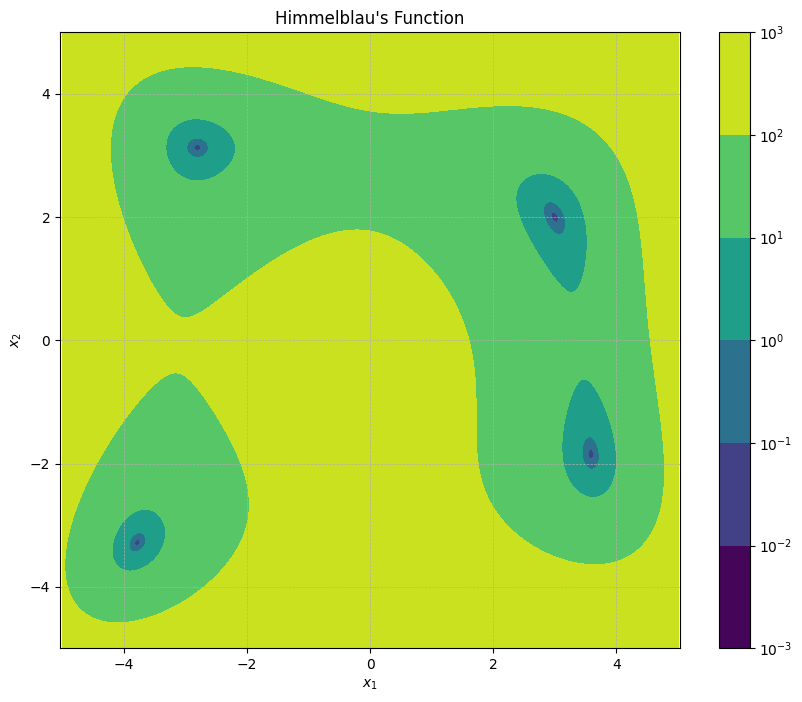

In [ ]:
N = 400
xlims = [-5, 5]
ylims = [-5, 5]
x1 = np.linspace(xlims[0], xlims[1], N)
x2 = np.linspace(ylims[0], ylims[1], N)
X1, X2 = np.meshgrid(x1, x2)
X = np.vstack([X1.ravel(), X2.ravel()]).T
Z = himmelblau_2d(X)

# plotting
plt.figure(figsize=(10, 8))
contour = plt.contourf(
    X1,
    X2,
    Z.reshape(N, N),
    norm=plt.cm.colors.LogNorm(vmin=Z.min(), vmax=Z.max()),
    cmap="viridis",
)
plt.colorbar(contour)
plt.title("Himmelblau's Function")
plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.axis("equal")
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.show()

In [ ]:
N_train = 50_000
X_train = DataSampler.sample_latin_hypercube(np.array([xlims, ylims]), N_train)

In [ ]:
ATOL = 1e-1
RTOL = 1e-1
surrogate = NearODESurrogate(data_dim=2, f_dim=1)
surrogate.train(
    X_train=X_train,
    f=himmelblau_2d,
    grad=grad_himmelblau_2d,
    NUM_INITIAL_CLUSTERS=50,
    MIN_PTS_PER_CLUSTER=100,
    ATOL=ATOL,
    RTOL=RTOL,
)
X_src = surrogate.get_source_centroids()
R_src = surrogate.R_src

# Select a subset of source centroids for clearer visualization
n_to_show = 200
np.random.seed(42)
rnd_indices = np.random.choice(X_src.shape[0], size=n_to_show, replace=False)
X_src_subset = X_src[rnd_indices]
R_src_subset = R_src[rnd_indices]

/tmp/ipykernel_39180/637518206.py:58: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


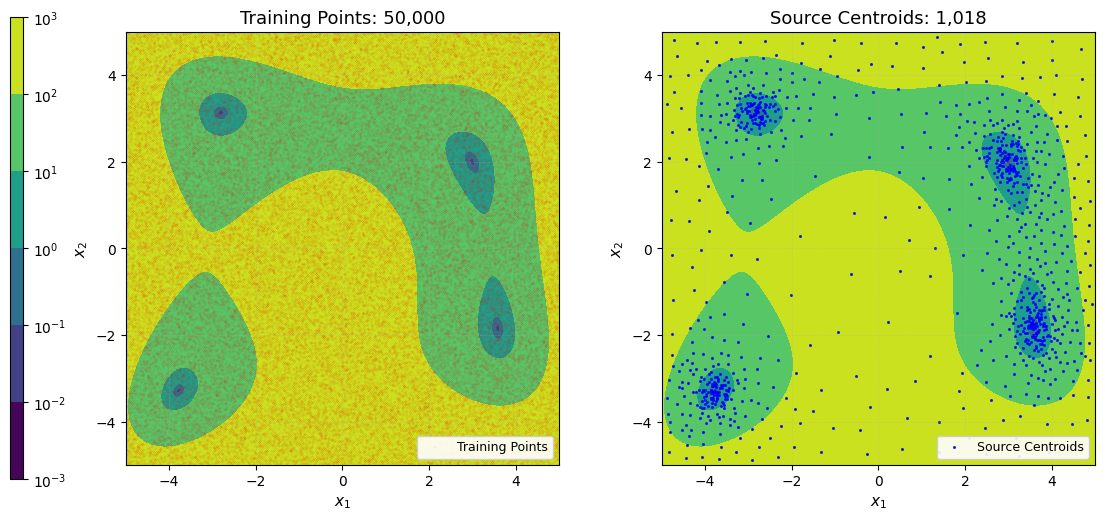

In [ ]:
# Plot training points and source centroids
fig = plt.figure(figsize=(14, 6))

# Main title
# fig.suptitle("Himmelblau's Function", fontweight="bold", y=0.96)

# Create gridspec for better control - colorbar on left
gs = fig.add_gridspec(1, 3, width_ratios=[0.03, 1, 1], wspace=0.35)

# Colorbar on the far left
cax = fig.add_subplot(gs[0])

# Left subplot - Training Points
ax1 = fig.add_subplot(gs[1])
contour1 = ax1.contourf(
    X1,
    X2,
    Z.reshape(N, N),
    norm=plt.cm.colors.LogNorm(vmin=Z.min(), vmax=Z.max()),
    cmap="viridis",
    levels=50,
)
ax1.scatter(
    X_train[:, 0], X_train[:, 1], c="red", s=0.01, alpha=0.5, label="Training Points"
)
ax1.set_title(f"Training Points: {X_train.shape[0]:,}", fontsize=13)
ax1.set_xlabel(r"$x_1$", fontsize=11)
ax1.set_ylabel(r"$x_2$", fontsize=11)
ax1.set_aspect("equal")
ax1.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.3)
ax1.legend(loc="lower right", framealpha=0.9, fontsize=9)

# Right subplot - Source Centroids

ax2 = fig.add_subplot(gs[2])
contour2 = ax2.contourf(
    X1,
    X2,
    Z.reshape(N, N),
    norm=plt.cm.colors.LogNorm(vmin=Z.min(), vmax=Z.max()),
    cmap="viridis",
    levels=50,
)
ax2.scatter(
    X_src[:, 0], X_src[:, 1], c="blue", s=1.5, alpha=0.8, label="Source Centroids"
)
ax2.set_title(f"Source Centroids: {X_src.shape[0]:,}", fontsize=13)
ax2.set_xlabel(r"$x_1$", fontsize=11)
ax2.set_ylabel(r"$x_2$", fontsize=11)
ax2.set_aspect("equal")
ax2.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.3)
ax2.legend(loc="lower right", framealpha=0.9, fontsize=9)

# Add colorbar to leftmost position
cbar = fig.colorbar(contour2, cax=cax)
# cbar.set_label("Function Value", rotation=90, labelpad=15, fontsize=11)

plt.tight_layout()
plt.show()

/tmp/ipykernel_39180/3609493809.py:74: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


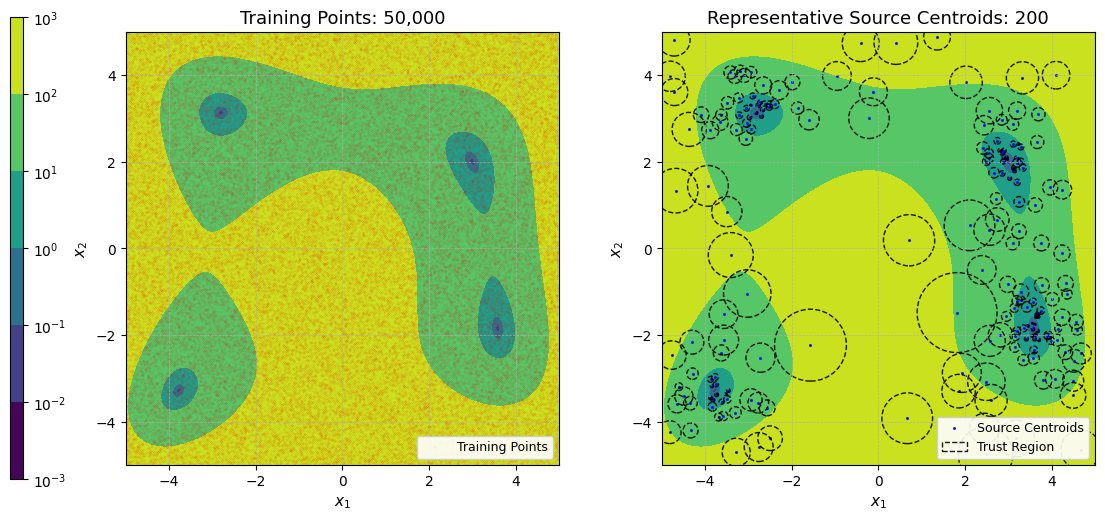

In [23]:
# Plot training points and source centroids
fig = plt.figure(figsize=(14, 6))

# Main title
# fig.suptitle("Himmelblau's Function", fontweight="bold", y=0.96)

# Create gridspec for better control - colorbar on left
gs = fig.add_gridspec(1, 3, width_ratios=[0.03, 1, 1], wspace=0.35)

# Colorbar on the far left
cax = fig.add_subplot(gs[0])

# Left subplot - Training Points
ax1 = fig.add_subplot(gs[1])
contour1 = ax1.contourf(
    X1,
    X2,
    Z.reshape(N, N),
    norm=plt.cm.colors.LogNorm(vmin=Z.min(), vmax=Z.max()),
    cmap="viridis",
    levels=50,
)
ax1.scatter(
    X_train[:, 0], X_train[:, 1], c="red", s=0.01, alpha=0.5, label="Training Points"
)
ax1.set_title(f"Training Points: {X_train.shape[0]:,}", fontsize=13)
ax1.set_xlabel(r"$x_1$", fontsize=11)
ax1.set_ylabel(r"$x_2$", fontsize=11)
ax1.set_aspect("equal")
ax1.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.9)
ax1.legend(loc="lower right", framealpha=0.9, fontsize=9)

# Right subplot - Source Centroids with centroids
ax2 = fig.add_subplot(gs[2])
contour2 = ax2.contourf(
    X1,
    X2,
    Z.reshape(N, N),
    norm=plt.cm.colors.LogNorm(vmin=Z.min(), vmax=Z.max()),
    cmap="viridis",
    levels=50,
)
ax2.scatter(
    X_src_subset[:, 0],
    X_src_subset[:, 1],
    c="blue",
    s=1.5,
    alpha=0.8,
    label="Source Centroids",
)

for i in range(X_src_subset.shape[0]):
    circle = plt.Circle(
        (X_src_subset[i, 0], X_src_subset[i, 1]),
        R_src_subset[i],
        color="k",
        fill=False,
        linestyle="--",
        alpha=0.9,
        label="Trust Region" if i == 0 else None,
    )
    ax2.add_artist(circle)
ax2.set_title(f"Representative Source Centroids: {n_to_show}", fontsize=13)
ax2.set_xlabel(r"$x_1$", fontsize=11)
ax2.set_ylabel(r"$x_2$", fontsize=11)
ax2.set_aspect("equal")
ax2.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.9)
ax2.legend(loc="lower right", framealpha=0.9, fontsize=9)

# Add colorbar to leftmost position
cbar = fig.colorbar(contour2, cax=cax)
# cbar.set_label("Function Value", rotation=90, labelpad=15, fontsize=11)

plt.tight_layout()
plt.show()

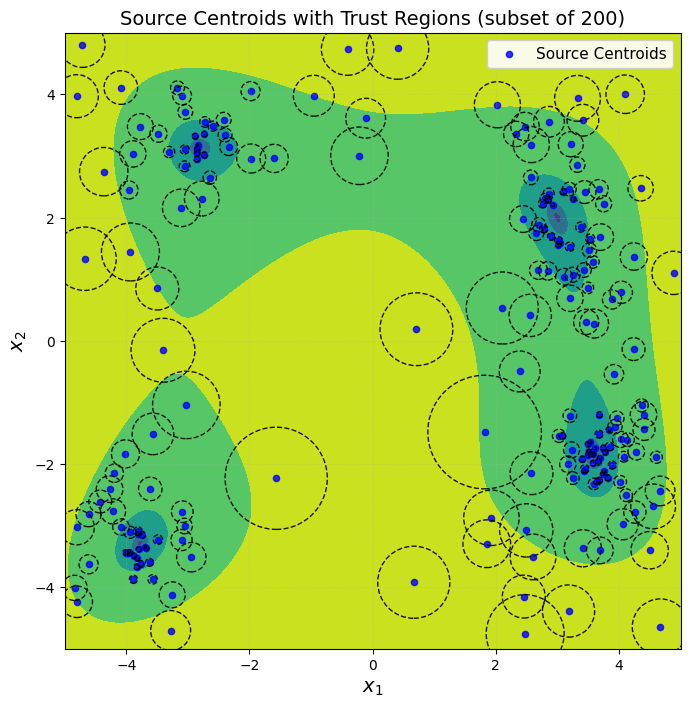

In [ ]:
R_src = surrogate.R_src

# Select a subset of source centroids for clearer visualization
n_to_show = 200
np.random.seed(42)
rnd_indices = np.random.choice(X_src.shape[0], size=n_to_show, replace=False)
X_src_subset = X_src[rnd_indices]
R_src_subset = R_src[rnd_indices]

# Plot source centroids with corresponding circles of radius R_src
fig, ax = plt.subplots(figsize=(8, 8))
contour = ax.contourf(
    X1,
    X2,
    Z.reshape(N, N),
    norm=plt.cm.colors.LogNorm(vmin=Z.min(), vmax=Z.max()),
    cmap="viridis",
)
ax.scatter(
    X_src_subset[:, 0],
    X_src_subset[:, 1],
    c="blue",
    s=20,
    alpha=0.8,
    label="Source Centroids",
)
for i in range(X_src_subset.shape[0]):
    circle = plt.Circle(
        (X_src_subset[i, 0], X_src_subset[i, 1]),
        R_src_subset[i],
        color="k",
        fill=False,
        linestyle="--",
        alpha=0.9,
    )
    ax.add_artist(circle)
ax.set_title(
    f"Source Centroids with Trust Regions (subset of {n_to_show})", fontsize=14
)
ax.set_xlabel(r"$x_1$", fontsize=14)
ax.set_ylabel(r"$x_2$", fontsize=14)
ax.set_aspect("equal")
ax.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.3)
ax.legend(loc="upper right", framealpha=0.9, fontsize=11)
plt.show()

In [ ]:
X_test = [[0.0, 0.0], [-2.0, 2.0], [3.0, 2.0], [2, -4.0]]
X_test = np.array(X_test)
Y_actual = himmelblau_2d(X_test)
Y_pred, outside_mask = surrogate.predict(
    X_test,
    ATOL=ATOL,
    RTOL=RTOL,
    k_NEIGHBOURS=1,
)

# plot predictions vs actual
for i, x in enumerate(X_test):
    print(
        f"Test Point {x}: Actual = {Y_actual[i,0]:.4f}, Predicted = {Y_pred[i,0]:.4f}, Outside Surrogate Domain: {outside_mask[i]}"
    )

Test Point [0. 0.]: Actual = 170.0000, Predicted = 178.3674, Outside Surrogate Domain: True
Test Point [-2.  2.]: Actual = 50.0000, Predicted = 48.2186, Outside Surrogate Domain: True
Test Point [3. 2.]: Actual = 0.0000, Predicted = -0.0458, Outside Surrogate Domain: True
Test Point [ 2. -4.]: Actual = 242.0000, Predicted = 234.5794, Outside Surrogate Domain: False
